# Ablation Study

1. AE vs AE + Feature selection (already present inside `feature_selection.ipynb`)
2. AAE vs AAE Fusion
3. AE + Fusion vs AAE + Fusion
4. Effects of Parameteres on AAE

In [1]:
import torch
import random
import numpy as np
import pandas as pd
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
from IPython.display import display

from dataset.kuka_splits import split_kuka_numpy
from dataset.kuka_dataset import KukaDataset
from processing.kuka_processing import KukaPreprocessor
from models.AE import AE
from models.AAE import AAE
from utils import plot_latent, plot_scores
from metrics import compute_pointwise_metrics

from train_ae import err_fn, build_dataloaders as build_ae_dataloaders
from train_aae import  (
    build_dataloaders as build_aae_fusion_dataloader, 
    compute_scores as compute_aae_scores, 
    train_outlier_estimator, 
    fuse_scores, 
    train_fusion_model, 
    compute_scores, 
    load_checkpoint
)


## 1. Configuration

In [ ]:
# Global Configurations
DATA_DIR = "./data"
AE_MODEL_PATH = "trained_models/ae_best.pth"
AAE_FUSION_MODEL_PATH = "trained_models/aae_bundle_best.pth"
SEED = 123
BATCH_SIZE = 1024
LATENT_DIM = 4
LR_AE = 1e-3
LR_D = 5e-5
LR_G = 1e-4
PRETRAIN_EPOCHS = 25 
THRESHOLD_AE = 0.087016761302948 # from validation notebook
THRESHOLD_AAE = 0.22363901138305664 # from validation notebook
EPOCHS = 50 
TOP_K_AE = 2
TOP_K_AAE = 2
TOP_K_AAE_FUSION = 1
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
N_FEATURES_RAW = np.load(DATA_DIR + "/KukaNormal.npy").shape[1]


In [3]:
def set_seed(seed: int) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)

## 2. Utility functions

These functions keep the notebook self-contained while reusing the project objects: `KukaPreprocessor`, `KukaDataset`, `AE`, and `compute_threshold`.

In [4]:

def evaluate(model, test_loader, threshold, top_k):
    model.eval()
    all_preds, all_labels, all_errors = [], [], []
    with torch.no_grad():
        for x_batch, y_batch in test_loader:
            x_batch = x_batch.to(DEVICE)
            recon, _ = model(x_batch) 
            
            err = err_fn(recon, x_batch, top_k)
            preds = (err > threshold).int()
            
            all_preds.append(preds.cpu())
            all_labels.append(y_batch.cpu())
            all_errors.append(err.cpu())
            
    all_preds = torch.cat(all_preds)
    all_labels = torch.cat(all_labels)
    all_errors = torch.cat(all_errors)

    return all_preds, all_labels, all_errors


def create_and_display_metrics_df(metrics_list, sort_by=None, ascending=False):
    # Create the DataFrame from the list of dictionaries

    if isinstance(metrics_list, dict):
        metrics_list = [metrics_list]

    df = pd.DataFrame(metrics_list)
    
    # Sort the DataFrame if a sort column is provided and exists
    if sort_by and sort_by in df.columns:
        df = df.sort_values(by=sort_by, ascending=ascending).reset_index(drop=True)
        
    display(df)
    
    return df



## 5. AAE vs AAE Fusion

In [5]:
aae, outlier_estimator, fusion_model  = load_checkpoint(AAE_FUSION_MODEL_PATH, DEVICE)

### AAE 

/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,precision,recall,f1,f2,accuracy,balanced_accuracy,pr_auc,average_precision,n_samples,n_normal,n_anomaly
0,0.958676,0.730512,0.829184,0.767022,0.888053,0.855932,0.920335,0.920341,55839,35070,20769


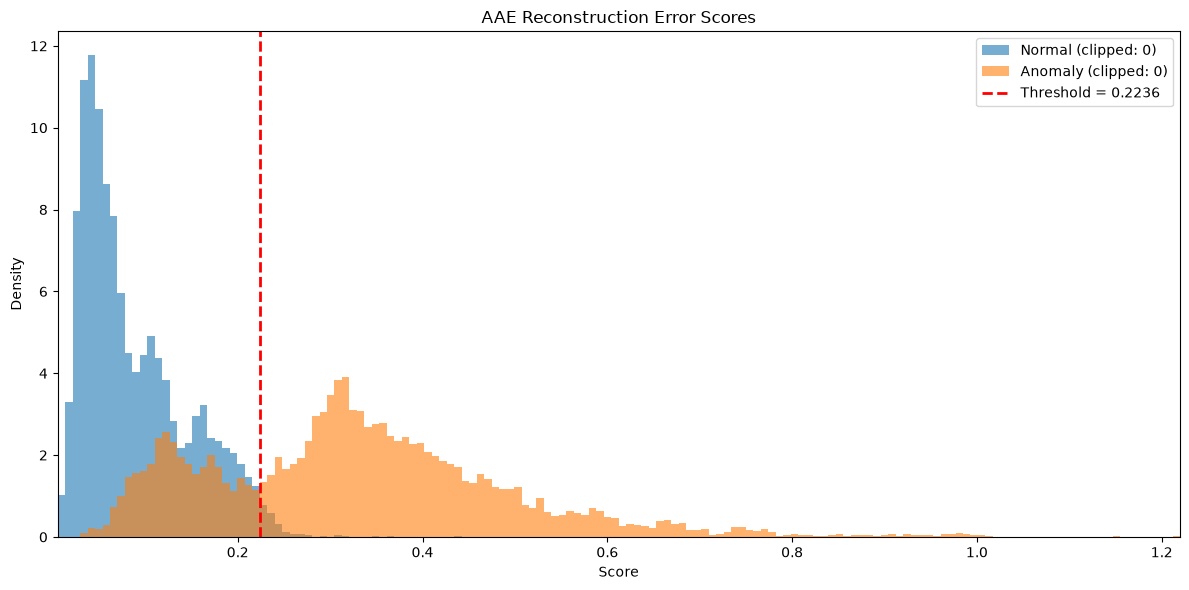

In [6]:
train_dataset, train_loader, val_loader, test_loader, _ = build_ae_dataloaders(DATA_DIR, BATCH_SIZE, seed=SEED)
x, y = train_dataset[0]
input_dim = x.shape[0]

all_preds, all_labels, all_errors = evaluate(aae, test_loader, THRESHOLD_AAE, TOP_K_AAE)
metrics = compute_pointwise_metrics(all_labels, all_preds, all_errors, beta=2.0)
create_and_display_metrics_df(metrics)
plot_scores(all_errors, all_labels, THRESHOLD_AAE, "AAE Reconstruction Error Scores")

### AAE + Fusion

/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,precision,recall,f1,f2,accuracy,balanced_accuracy,pr_auc,average_precision,n_samples,n_normal,n_anomaly
0,0.968885,0.926573,0.947257,0.934737,0.961622,0.954476,0.988557,0.988558,55839,35070,20769


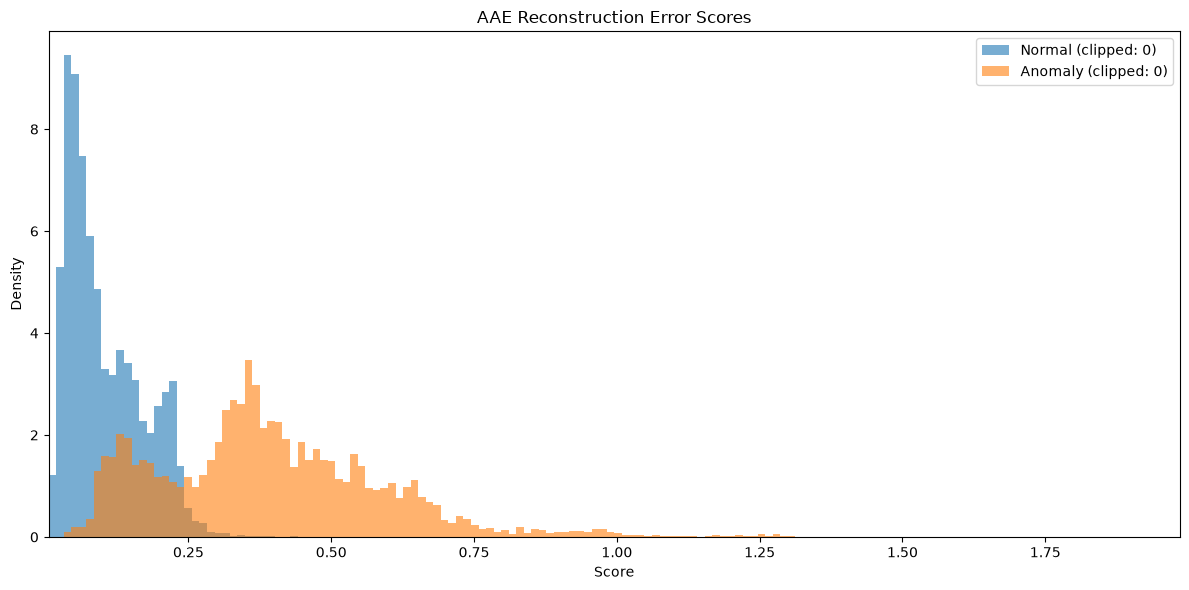

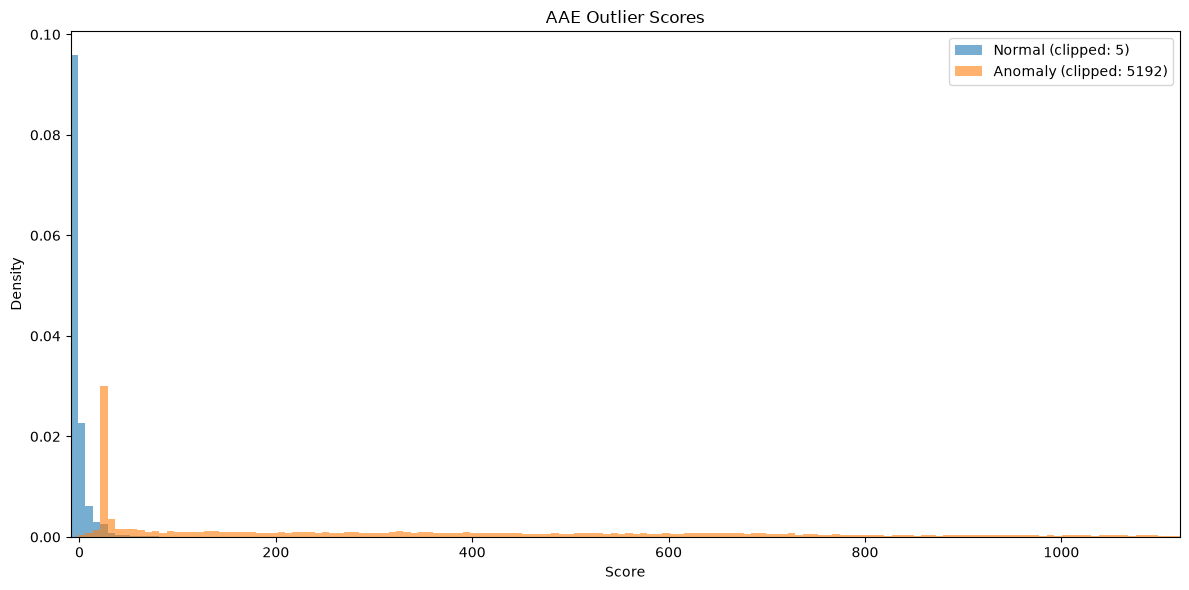

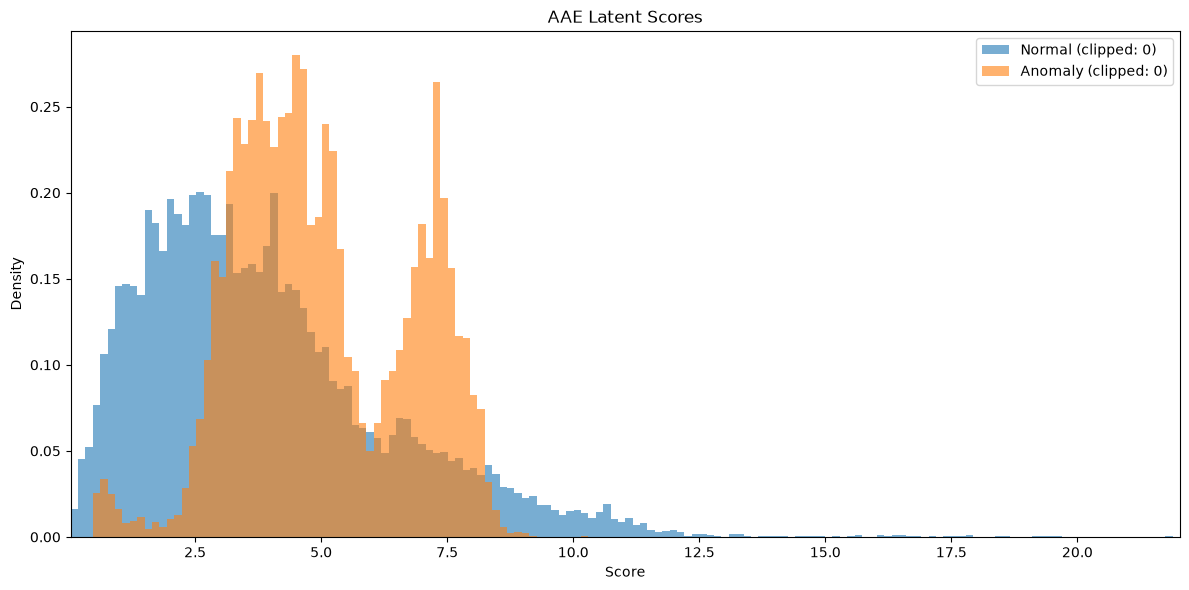

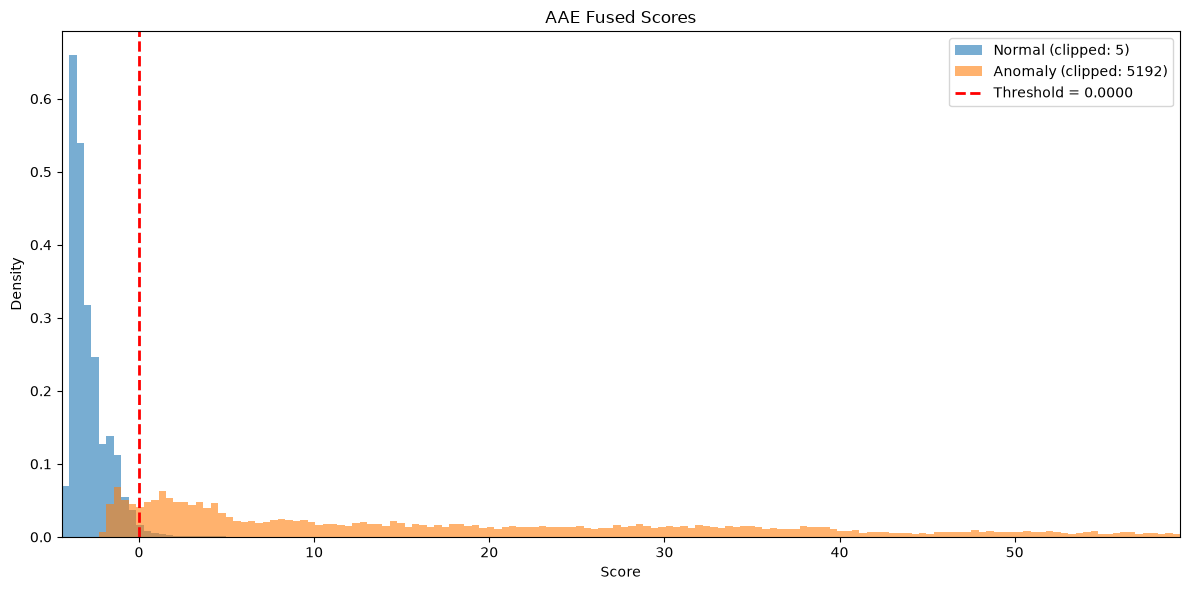

In [7]:
train_loader, train_fuse_loader, val_loader, test_loader, _ = build_aae_fusion_dataloader(DATA_DIR, BATCH_SIZE, seed=SEED)

recon_scores, outlier_scores, latent_scores, labels = compute_scores(aae, test_loader, TOP_K_AAE_FUSION, outlier_estimator)
scores = fuse_scores(fusion_model, recon_scores, outlier_scores, latent_scores)

# predict positive score as anomaly (threshold fixed to 0)
t = 0.0
preds = (scores > t).int()

metrics = compute_pointwise_metrics(labels, preds, scores)
create_and_display_metrics_df(metrics)
plot_scores(recon_scores, labels, None, "AAE Reconstruction Error Scores")
plot_scores(outlier_scores, labels,  None, "AAE Outlier Scores", clip=True)
plot_scores(latent_scores, labels, None, "AAE Latent Scores")
plot_scores(scores, labels, t, "AAE Fused Scores", clip=True)



## 6. AE + Fusion vs AAE + Fusion

### AE + Fusion

/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Training fusion model...


,precision,recall,f1,f2,accuracy,balanced_accuracy,pr_auc,average_precision,n_samples,n_normal,n_anomaly
0,0.897828,0.885551,0.891647,0.887979,0.919948,0.912935,0.95777,0.957774,55839,35070,20769


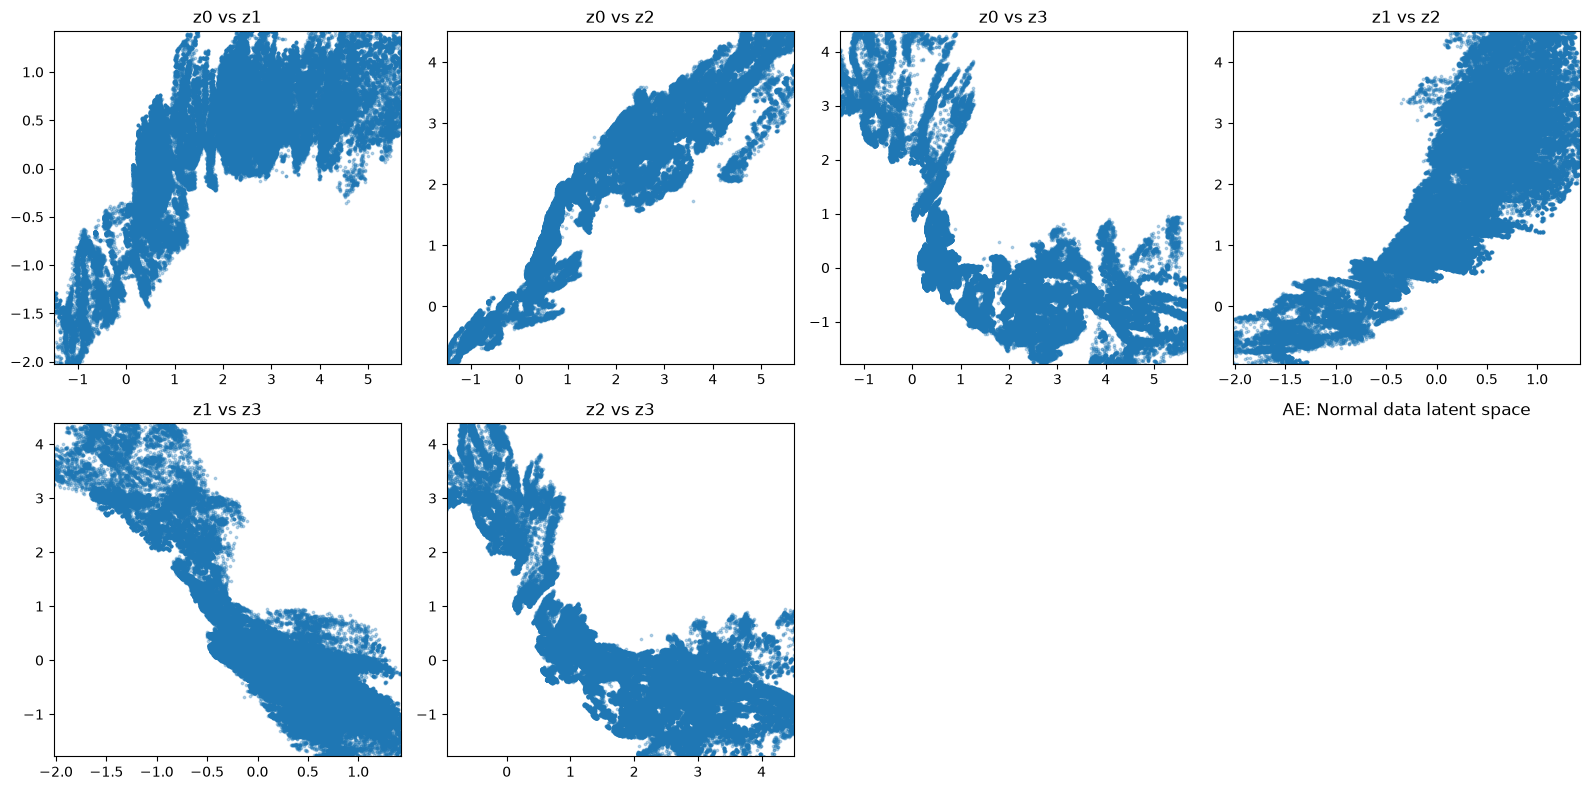

In [8]:
train_loader, train_fuse_loader, val_loader, test_loader, _ = build_aae_fusion_dataloader(DATA_DIR, BATCH_SIZE, seed=SEED)

ae = AE(input_dim, LATENT_DIM).to(DEVICE)
ae.load_state_dict(torch.load(AE_MODEL_PATH, map_location=DEVICE))
estimator = train_outlier_estimator(ae, train_loader)

# compute and fuse scores on validation set
print("Training fusion model...")
recon_scores, outlier_scores, latent_scores, labels = compute_scores(ae, train_fuse_loader, TOP_K_AE, estimator)
fusion_model = train_fusion_model(labels, recon_scores, outlier_scores, latent_scores)


recon_scores, outlier_scores, latent_scores, labels = compute_scores(ae, test_loader, TOP_K_AE, estimator)
scores = fuse_scores(fusion_model, recon_scores, outlier_scores, latent_scores)

# predict positive score as anomaly (threshold fixed to 0)
t = 0.0
preds = (scores > t).int()

metrics = compute_pointwise_metrics(labels, preds, scores)
create_and_display_metrics_df(metrics)
plot_latent(ae, train_loader, LATENT_DIM, title="AE: Normal data latent space")


### AAE + Fusion

/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Users/klejsizeqaj/Desktop/PoliTo/Magistrale/Machine Learing for Applications/industrial-robot-anomaly-detection/venv/lib/python3.11/site-packages/numpy/lib/_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


,precision,recall,f1,f2,accuracy,balanced_accuracy,pr_auc,average_precision,n_samples,n_normal,n_anomaly
0,0.968885,0.926573,0.947257,0.934737,0.961622,0.954476,0.988557,0.988558,55839,35070,20769


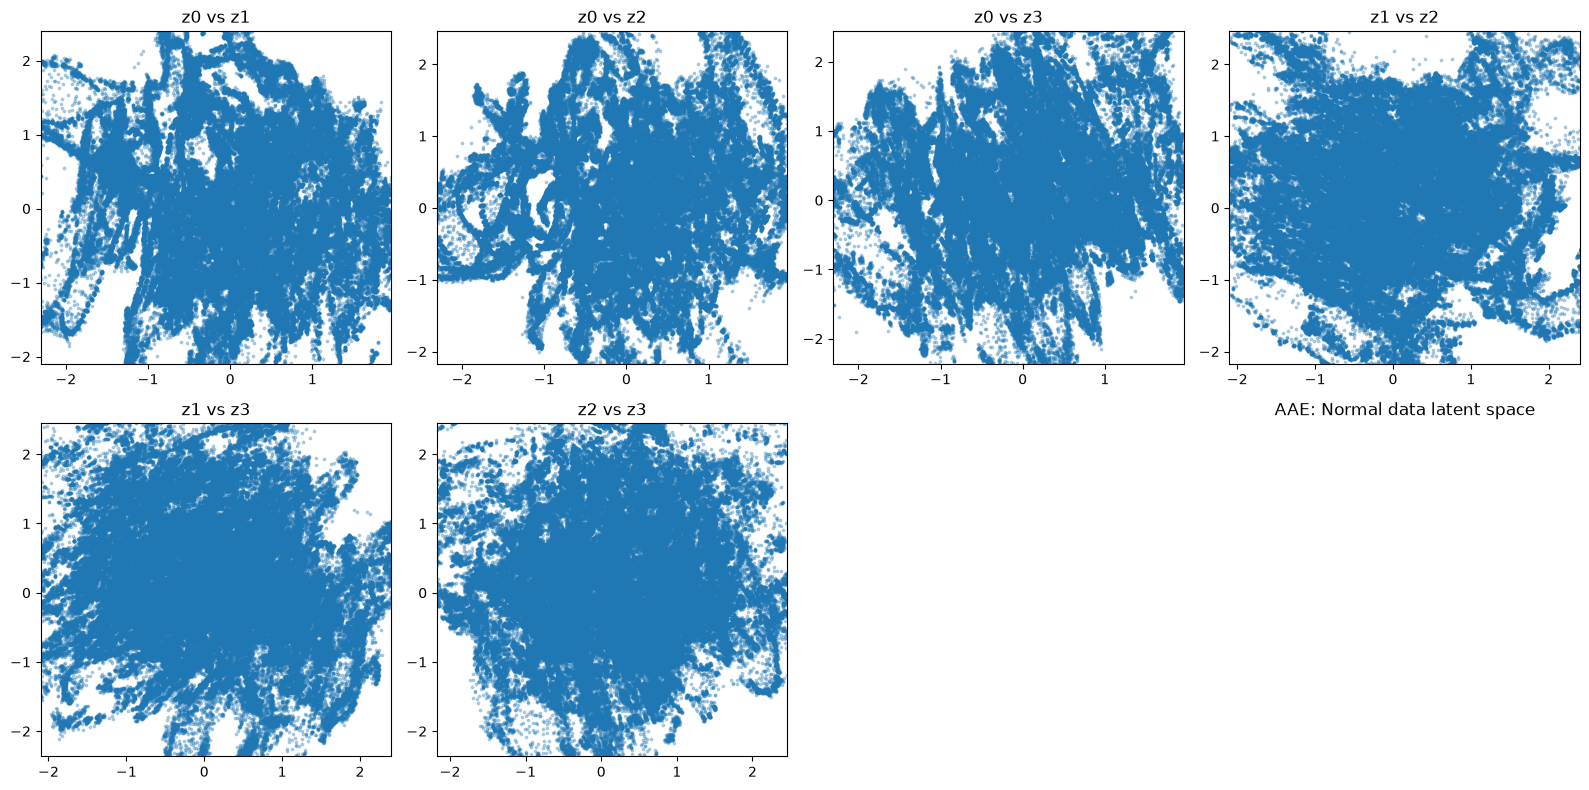

In [11]:
aae, outlier_estimator, fusion_model  = load_checkpoint(AAE_FUSION_MODEL_PATH, DEVICE)
train_loader, train_fuse_loader, val_loader, test_loader, _ = build_aae_fusion_dataloader(DATA_DIR, BATCH_SIZE, seed=SEED)

recon_scores, outlier_scores, latent_scores, labels = compute_scores(aae, test_loader, TOP_K_AAE_FUSION, outlier_estimator)
scores = fuse_scores(fusion_model, recon_scores, outlier_scores, latent_scores)

# predict positive score as anomaly (threshold fixed to 0)
t = 0.0
preds = (scores > t).int()

metrics = compute_pointwise_metrics(labels, preds, scores)
create_and_display_metrics_df(metrics)
plot_latent(aae, train_loader, LATENT_DIM, title="AAE: Normal data latent space")


## 7. Parameters Effect on AAE

We evaluate the effects of `top_k` on the AAE perfomance. Specifically, we vary `top_k` within [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, input_dim] set.

### Varying TOP-K

In [13]:
top_ks_to_test = [1, 2, 3, 5, 10, 15, 20, 25, 30, 40, input_dim]
results = []

print("\nStarting Top-K Search...")
for k in top_ks_to_test:

    print("-" * 60)
    print(f"Testing AAE + fusion -> top_k: {k}")
    
    recon_scores, outlier_scores, latent_scores, labels = compute_aae_scores(aae, train_fuse_loader, k, outlier_estimator)
    fusion_model = train_fusion_model(labels, recon_scores, outlier_scores, latent_scores)
    
    recon_scores, outlier_scores, latent_scores, labels = compute_aae_scores(aae, test_loader, k, outlier_estimator)
    scores = fuse_scores(fusion_model, recon_scores, outlier_scores, latent_scores)
    
   
    t = 0.0
    preds = (scores > t).int()
    
    metrics = compute_pointwise_metrics(labels, preds, scores, 2.0)
    metrics["top_k"] = k

    results.append(metrics)
    
_ = create_and_display_metrics_df(results)


Starting Top-K Search...
------------------------------------------------------------
Testing AAE + fusion -> top_k: 1
------------------------------------------------------------
Testing AAE + fusion -> top_k: 2
------------------------------------------------------------
Testing AAE + fusion -> top_k: 3
------------------------------------------------------------
Testing AAE + fusion -> top_k: 5
------------------------------------------------------------
Testing AAE + fusion -> top_k: 10
------------------------------------------------------------
Testing AAE + fusion -> top_k: 15
------------------------------------------------------------
Testing AAE + fusion -> top_k: 20
------------------------------------------------------------
Testing AAE + fusion -> top_k: 25
------------------------------------------------------------
Testing AAE + fusion -> top_k: 30
------------------------------------------------------------
Testing AAE + fusion -> top_k: 40
----------------------------

,precision,recall,f1,f2,accuracy,balanced_accuracy,pr_auc,average_precision,n_samples,n_normal,n_anomaly,top_k
0,0.968885,0.926573,0.947257,0.934737,0.961622,0.954476,0.988557,0.988558,55839,35070,20769,1
1,0.963382,0.922192,0.942337,0.930146,0.958022,0.950717,0.987628,0.987628,55839,35070,20769,2
2,0.955637,0.919977,0.937468,0.926894,0.954351,0.947342,0.987062,0.987062,55839,35070,20769,3
3,0.950284,0.917569,0.933640,0.923931,0.951486,0.944570,0.986636,0.986637,55839,35070,20769,5
4,0.949860,0.915788,0.932513,0.922405,0.950698,0.943580,0.987091,0.987091,55839,35070,20769,10
5,0.950357,0.916221,0.932977,0.922851,0.951038,0.943939,0.987778,0.987778,55839,35070,20769,15
6,0.950825,0.916077,0.933127,0.922822,0.951163,0.944009,0.988147,0.988147,55839,35070,20769,20
7,0.950426,0.918484,0.934182,0.924700,0.951862,0.945056,0.988257,0.988258,55839,35070,20769,25
8,0.949541,0.921469,0.935295,0.926950,0.952578,0.946235,0.988244,0.988244,55839,35070,20769,30
9,0.948546,0.926670,0.937480,0.930964,0.954029,0.948450,0.988105,0.988106,55839,35070,20769,40
